# Время поездки домой в Лондоне
**Семинар по регрессии · 90 минут**

Все поездки начинаются в одном месте в центре Лондона. Предсказываем время до дома по одной синтетической выгрузке. Восстановим единицы расстояния, переведём процент пути пешком в метры, проверим выбросы и обучим `LinearRegression`.

**Как работаем.** Ячейки «Пишем вместе» занимают около 36 минут.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

### 0. Подготовка данных

Эта ячейка создаёт синтетический CSV для семинара.

In [2]:
rng = np.random.default_rng(42)
data_dir = Path("seminar_data")
data_dir.mkdir(exist_ok=True)

n = 360
home_zone = rng.integers(1, 7, size=n)
distance_m = np.rint(
    np.clip(1800 + 2800 * (home_zone - 1) + rng.normal(0, 1500, n), 700, 26000)
).astype(int)
walk_pct = rng.integers(4, 30, size=n)
walk_m_truth = distance_m * walk_pct / 100
transfers = rng.integers(0, 4, n)
rush_hour = rng.binomial(1, 0.45, n)
transport = rng.choice(["метро", "автобус", "поезд"], n, p=[0.46, 0.34, 0.20])

# Условные зависимости для упражнения, время не взято из расписания.
transport_minutes = pd.Series(transport).map({"метро": 0, "автобус": 10, "поезд": -5})
travel_time = np.maximum(
    5, 7 + 1.8 * distance_m / 1000 + 1.7 * (home_zone - 1)
    + 0.008 * walk_m_truth + 4.5 * transfers + 5 * rush_hour
    + transport_minutes + rng.normal(0, 3, n)
).round(1).to_numpy()
travel_time[[7, 61, 197, 310]] = [-12, 480, 720, 365]
travel_time[143] = 112

use_km = rng.random(n) < 0.5
distance_value = np.where(use_km, distance_m / 1000, distance_m)
distance_unit = pd.Series(np.where(use_km, "км", "м"), dtype="string")
missing_unit = rng.choice(n, size=70, replace=False)
distance_unit.iloc[missing_unit] = pd.NA

pd.DataFrame({
    "distance_value": distance_value,
    "distance_unit": distance_unit,
    "walk_pct": walk_pct,
    "home_zone": home_zone,
    "transport": transport,
    "transfers": transfers,
    "rush_hour": rush_hour,
    "travel_time_min": travel_time,
}).to_csv(data_dir / "commute.csv", index=False)

## 1. Знакомимся с выгрузкой · 10 мин

**Пишем вместе · 4 мин.** Одна строка — одна поездка из центра Лондона. `travel_time_min` — время в пути, наш таргет. `home_zone` — транспортная зона дома от 1 до 6. `transport` — основной вид транспорта. В `walk_pct` записан процент маршрута пешком от 0 до 100. Число пересадок записано в `transfers`, час пик — в `rush_hour` (0 или 1).

In [3]:
df = pd.read_csv(data_dir / "commute.csv")
display(df.head(8))

,distance_value,distance_unit,walk_pct,home_zone,transport,transfers,rush_hour,travel_time_min
0,2040.000,м,29,1,поезд,1,0,19.6
1,12.822,км,19,5,автобус,1,1,72.7
2,10629.000,NaN,22,4,метро,0,0,49.8
3,9.359,NaN,16,3,метро,1,1,52.1
4,7.729,км,4,3,метро,0,1,35.6
5,15.184,км,6,6,автобус,0,0,55.9
6,3459.000,м,10,1,поезд,1,0,14.6
7,13.643,км,10,5,поезд,0,0,-12.0


In [4]:
display(df["travel_time_min"].describe().round(1))

count    360.0
mean      52.6
std       49.6
min      -12.0
25%       33.2
50%       48.9
75%       63.2
max      720.0
Name: travel_time_min, dtype: float64

## 2. Восстанавливаем единицы и создаём признак · 15 мин

**Пишем вместе · 8 мин.** В выгрузке расстояние разделено на число `distance_value` и единицу `distance_unit`. Когда единица заполнена, верим ей. Только при пропуске применяем правило этой выгрузки: **меньше 30 — километры, от 30 — метры**. Затем переводим все расстояния в метры.

Переводим процент пешего пути в метры по формуле `walk_m = distance_m * walk_pct / 100`. Если маршрут длиной 4 км, то 25% — это 1000 м пешком.

In [5]:
in_km = df["distance_unit"].eq("км") | (
    df["distance_unit"].isna() & df["distance_value"].lt(30)
)
df["distance_m"] = np.where(in_km, df["distance_value"] * 1000, df["distance_value"])
df["walk_m"] = df["distance_m"] * df["walk_pct"] / 100

In [6]:
display(df.loc[df["distance_unit"].isna(),
               ["distance_value", "distance_unit", "distance_m", "walk_pct", "walk_m"]].head(8))

,distance_value,distance_unit,distance_m,walk_pct,walk_m
2,10629.000,NaN,10629.0,22,2338.38
3,9.359,NaN,9359.0,16,1497.44
12,15476.000,NaN,15476.0,18,2785.68
15,12425.000,NaN,12425.0,21,2609.25
18,14.458,NaN,14458.0,19,2747.02
24,15.111,NaN,15111.0,26,3928.86
28,10127.000,NaN,10127.0,12,1215.24
31,3.283,NaN,3283.0,23,755.09


## 3. Проверяем выбросы · 20 мин

**Пишем вместе · 8 мин.** Правилом 1,5 IQR отмечаем строки для проверки. Нижняя и верхняя границы строятся по первому и третьему квартилям времени в пути.

In [7]:
duration = df["travel_time_min"]
q1, q3 = duration.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Границы IQR: от {lower:.1f} до {upper:.1f} мин")

Границы IQR: от -11.8 до 108.3 мин


In [8]:
suspect = (duration < lower) | (duration > upper)
display(df.loc[suspect].sort_values("travel_time_min"))

,distance_value,distance_unit,walk_pct,home_zone,transport,transfers,rush_hour,travel_time_min,distance_m,walk_m
7,13.643,км,10,5,поезд,0,0,-12.0,13643.0,1364.30
143,8.574,NaN,24,3,автобус,3,1,112.0,8574.0,2057.76
310,10.845,км,21,4,метро,0,1,365.0,10845.0,2277.45
61,11.406,км,8,5,метро,0,0,480.0,11406.0,912.48
197,2.631,км,26,1,автобус,3,0,720.0,2631.0,684.06


Для этой синтетической выгрузки оставляем поездки длительностью больше нуля и до трёх часов. Поездка на 112 минут выходит за границы IQR, но остаётся в допустимом диапазоне.

In [9]:
invalid = (duration <= 0) | (duration > 180)
df_valid = df.loc[~invalid].copy()
print("Удалили строк:", invalid.sum())

Удалили строк: 4


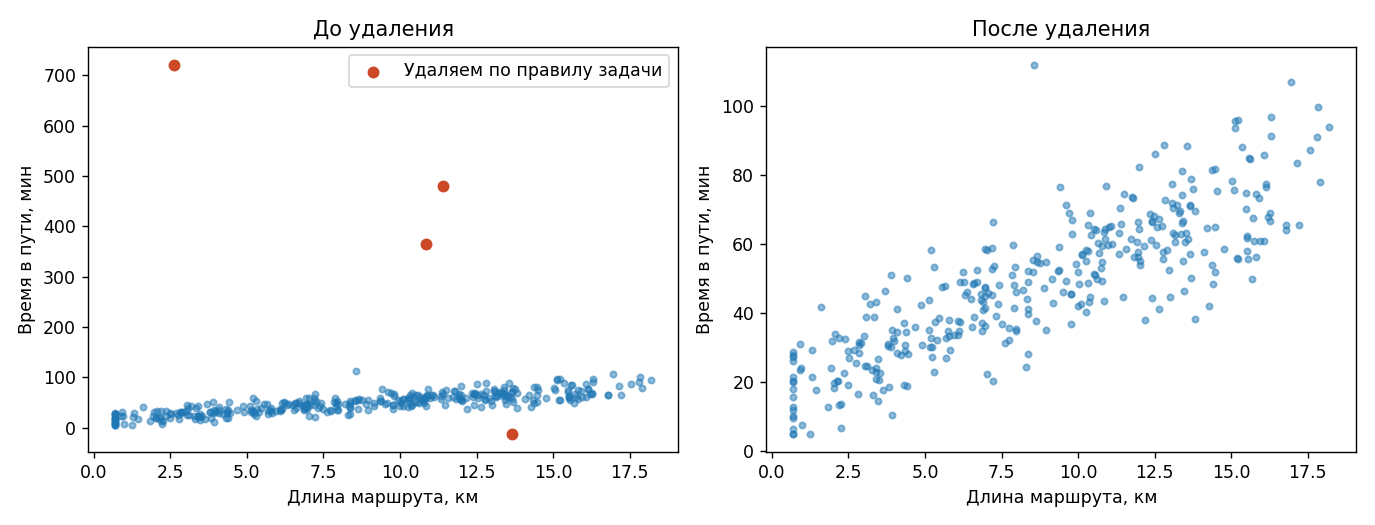

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
axes[0].scatter(df["distance_m"] / 1000, duration, s=13, alpha=0.5)
axes[0].scatter(
    df.loc[invalid, "distance_m"] / 1000, duration[invalid],
    s=34, color="#cc4928", label="Удаляем по правилу задачи",
)
axes[0].legend()
axes[0].set_title("До удаления")
axes[1].scatter(df_valid["distance_m"] / 1000, df_valid["travel_time_min"], s=13, alpha=0.5)
axes[1].set_title("После удаления")
for ax in axes:
    ax.set(xlabel="Длина маршрута, км", ylabel="Время в пути, мин")
fig.tight_layout()
plt.show()

## 4. Кодируем транспорт, зону оставляем числом · 5 мин

Вид транспорта — категория: метро, автобус и поезд не образуют шкалу. Его закодируем через one-hot. Зона дома, напротив, упорядочена. Все поездки у нас начинаются в одной точке в центре, поэтому больший номер зоны обычно означает поездку дальше от центра. Для этой задачи оставим `home_zone` числом.

In [11]:
numeric_features = ["distance_m", "walk_m", "home_zone", "transfers", "rush_hour"]
features = numeric_features + ["transport"]
target_column = "travel_time_min"

display(df_valid.groupby("home_zone")["distance_m"].agg(["count", "median"]).round(0))
display(df_valid["transport"].value_counts())

,count,median
home_zone,,
1,59,2075.0
2,58,5007.0
3,66,7189.0
4,57,10429.0
5,69,13010.0
6,47,15556.0


transport
метро      164
автобус    111
поезд       81
Name: count, dtype: int64

## 5. Готовим признаки и обучаем модель · 20 мин

**Пишем вместе · 12 мин.** Один раз делим данные на train и test. В следующих ячейках по очереди масштабируем числовые признаки, кодируем транспорт, объединяем признаки и обучаем `LinearRegression`. Скейлер и кодировщик обучаем только на train.

In [12]:
X = df_valid[features]
y = df_valid[target_column]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Обучение:", len(X_train), "| Тест:", len(X_test))

Обучение: 284 | Тест: 72


### Масштабируем числовые признаки

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[numeric_features])
X_test_scaled = scaler.transform(X_test[numeric_features])

In [14]:
display(pd.DataFrame({
    "До": X_train[numeric_features].std(ddof=0),
    "После": X_train_scaled.std(axis=0),
}).round(2))

,До,После
distance_m,4698.38,1.0
walk_m,1109.78,1.0
home_zone,1.65,1.0
transfers,1.11,1.0
rush_hour,0.50,1.0


### Кодируем вид транспорта

In [15]:
encoder = OneHotEncoder(handle_unknown="ignore")
X_train_encoded = encoder.fit_transform(X_train[["transport"]]).toarray()
X_test_encoded = encoder.transform(X_test[["transport"]]).toarray()

In [16]:
display(pd.DataFrame(
    X_train_encoded[:5].astype(int),
    columns=encoder.get_feature_names_out(),
    index=X_train.index[:5],
))

,transport_автобус,transport_метро,transport_поезд
349,0,1,0
336,0,0,1
185,0,1,0
77,0,1,0
340,0,0,1


### Собираем признаки и обучаем линейную регрессию

In [17]:
X_train_ready = np.column_stack([X_train_scaled, X_train_encoded])
X_test_ready = np.column_stack([X_test_scaled, X_test_encoded])

model = LinearRegression()
model.fit(X_train_ready, y_train)

## 6. Считаем MAE, MSE и MAPE · 15 мин

**Пишем вместе · 4 мин.** Предсказываем время поездки на тесте. Реализуем три метрики на NumPy. В MAE ошибки остаются в минутах, в MSE — в минутах в квадрате, в MAPE — в процентах от фактического времени. Все проверенные значения таргета положительные.

In [18]:
y_true = y_test.to_numpy()
y_pred = model.predict(X_test_ready)
display(pd.DataFrame({"Факт, мин": y_true, "Прогноз, мин": y_pred}, index=X_test.index).head().round(1))

,"Факт, мин","Прогноз, мин"
230,54.8,58.1
43,45.9,44.1
259,76.7,74.3
184,46.1,53.8
57,5.0,8.2


In [19]:
def mae(y, pred):
    return np.mean(np.abs(y - pred))


def mse(y, pred):
    return np.mean((y - pred) ** 2)


def mape(y, pred):
    return 100 * np.mean(np.abs((y - pred) / y))

In [20]:
def evaluate(actual, prediction):
    return {
        "MAE, мин": mae(actual, prediction),
        "MSE, мин²": mse(actual, prediction),
        "MAPE, %": mape(actual, prediction),
    }


baseline = np.full(len(y_true), y_train.median())
display(pd.DataFrame({
    "Медиана train": evaluate(y_true, baseline),
    "Линейная регрессия": evaluate(y_true, y_pred),
}).T.round(2))

,"MAE, мин","MSE, мин²","MAPE, %"
Медиана train,16.32,385.59,64.93
Линейная регрессия,2.39,8.74,7.99


## 7. Проверяем, что изменили выбросы · 5 мин

Повторим обучение той же линейной регрессии. В обучающую часть вернём четыре заведомо ошибочные записи и сравним метрики **на том же тесте**. Так между двумя запусками меняются только эти четыре строки в обучении.

Для эксперимента с выбросами и кросс-валидации используем одну и ту же функцию. Передаём ей обучающие данные и строки для прогноза, получаем массив прогнозов.

In [21]:
def fit_and_predict(X_train, y_train, X_eval):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train[numeric_features])
    X_eval_scaled = scaler.transform(X_eval[numeric_features])

    encoder = OneHotEncoder(handle_unknown="ignore")
    X_train_encoded = encoder.fit_transform(X_train[["transport"]]).toarray()
    X_eval_encoded = encoder.transform(X_eval[["transport"]]).toarray()

    X_train_ready = np.column_stack([X_train_scaled, X_train_encoded])
    X_eval_ready = np.column_stack([X_eval_scaled, X_eval_encoded])

    model = LinearRegression()
    model.fit(X_train_ready, y_train)
    return model.predict(X_eval_ready)

In [22]:
bad_train = df.loc[invalid, features + [target_column]]
X_noisy = pd.concat([X_train, bad_train[features]])
y_noisy = pd.concat([y_train, bad_train[target_column]])
assert X_noisy.index.intersection(X_test.index).empty

y_pred_noisy = fit_and_predict(X_noisy, y_noisy, X_test)

In [23]:
display(pd.DataFrame({
    "С ошибочными строками": evaluate(y_true, y_pred_noisy),
    "После проверки": evaluate(y_true, y_pred),
}).T.round(2))

,"MAE, мин","MSE, мин²","MAPE, %"
С ошибочными строками,5.80,51.10,19.07
После проверки,2.39,8.74,7.99


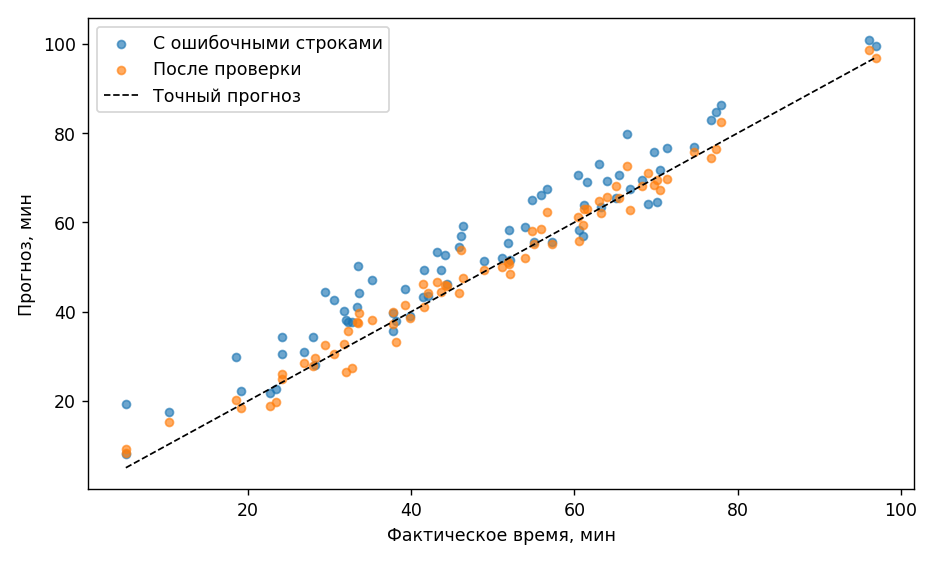

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(y_true, y_pred_noisy, s=21, alpha=0.65, label="С ошибочными строками")
ax.scatter(y_true, y_pred, s=21, alpha=0.65, label="После проверки")
bounds = [y_true.min(), y_true.max()]
ax.plot(bounds, bounds, "--", color="black", linewidth=1, label="Точный прогноз")
ax.set(xlabel="Фактическое время, мин", ylabel="Прогноз, мин")
ax.legend()
fig.tight_layout()
plt.show()

## Если осталось время

### MAE и MSE: две обученные прямые

Берём одни и те же обучающие маршруты с четырьмя ошибочными строками. Для графика оставляем один признак — длину маршрута.

- **MSE.** `LinearRegression` минимизирует сумму квадратов ошибок. У среднего квадрата тот же минимум.
- **MAE.** В `SGDRegressor` задаём `loss="epsilon_insensitive"` и `epsilon=0`. Тогда лосс равен абсолютной ошибке. `penalty=None` отключает регуляризацию.

In [25]:
X_distance = X_noisy[["distance_m"]].to_numpy() / 1000

model_mse = LinearRegression().fit(X_distance, y_noisy)
model_mae = SGDRegressor(
    loss="epsilon_insensitive", epsilon=0, penalty=None,
    learning_rate="constant", eta0=0.001,
    max_iter=3000, tol=None, average=True, random_state=42,
).fit(X_distance, y_noisy)

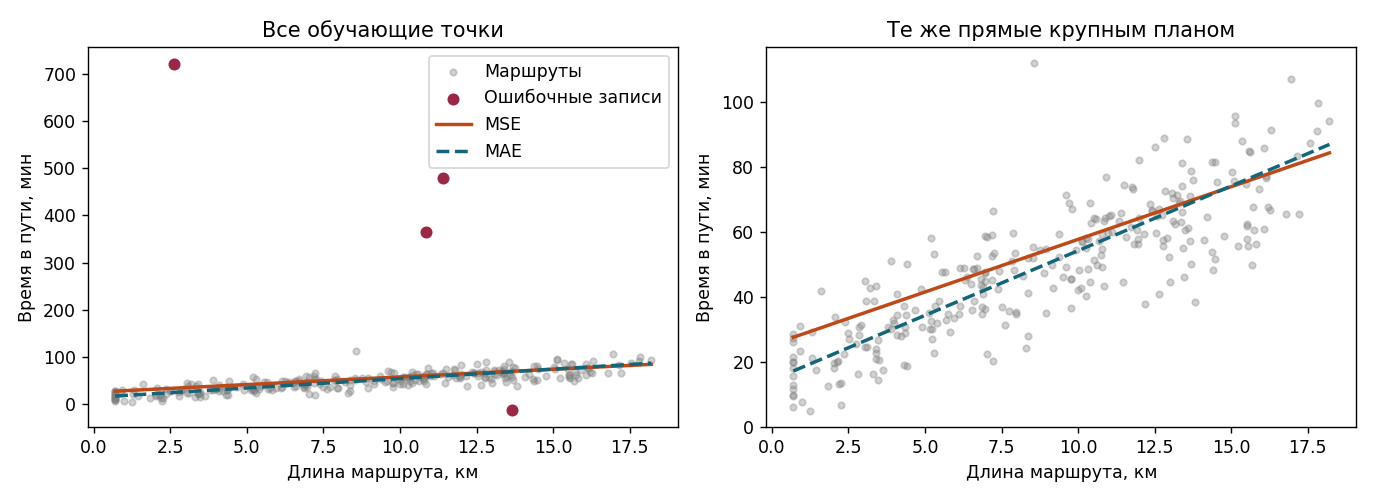

In [26]:
distance_line = np.linspace(X_distance.min(), X_distance.max(), 100).reshape(-1, 1)
bad_mask = X_noisy.index.isin(bad_train.index)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax in axes:
    ax.scatter(X_distance[~bad_mask, 0], y_noisy[~bad_mask], s=14, alpha=0.35,
               color="gray", label="Маршруты")
    ax.scatter(X_distance[bad_mask, 0], y_noisy[bad_mask], s=35,
               color="#992846", label="Ошибочные записи")
    ax.plot(distance_line[:, 0], model_mse.predict(distance_line), color="#bd4919",
            linewidth=2, label="MSE")
    ax.plot(distance_line[:, 0], model_mae.predict(distance_line), color="#146579",
            linestyle="--", linewidth=2, label="MAE")
    ax.set(xlabel="Длина маршрута, км", ylabel="Время в пути, мин")

axes[0].set_title("Все обучающие точки")
axes[0].legend()
axes[1].set_title("Те же прямые крупным планом")
axes[1].set_ylim(0, y_train.max() + 5)
fig.tight_layout()
plt.show()

На правом графике увеличен диапазон обычных поездок. При обучении по MSE ошибки возводятся в квадрат, поэтому длинные выбросы сильнее тянут прямую вверх.
    
### Коэффициенты основной модели

Для числовых признаков делим коэффициенты на стандартные отклонения, чтобы вернуться к исходным единицам. Каждый коэффициент читаем при фиксированных остальных признаках.

In [27]:
weights = pd.DataFrame({
    "признак": numeric_features,
    "шаг": ["1 км", "100 м пешком", "1 зона", "1 пересадка", "переход к часу пик"],
    "изменение прогноза, мин": model.coef_[:len(numeric_features)] / scaler.scale_
    * np.array([1000, 100, 1, 1, 1]),
})
display(weights.round(2))

,признак,шаг,"изменение прогноза, мин"
0,distance_m,1 км,1.70
1,walk_m,100 м пешком,0.85
2,home_zone,1 зона,1.60
3,transfers,1 пересадка,4.77
4,rush_hour,переход к часу пик,5.11


### Кросс-валидация

Проверяем модель на пяти разбиениях обучающей части. В каждом фолде заново обучаем скейлер и кодировщик. Отложенный тест в кросс-валидации не участвует.

In [28]:
cv_scores = []
folds = KFold(n_splits=5, shuffle=True, random_state=42)
for fold, (train_ids, validation_ids) in enumerate(folds.split(X_train), start=1):
    validation_pred = fit_and_predict(
        X_train.iloc[train_ids], y_train.iloc[train_ids], X_train.iloc[validation_ids]
    )
    cv_scores.append({
        "Фолд": fold,
        **evaluate(y_train.iloc[validation_ids].to_numpy(), validation_pred),
    })

fold_results = pd.DataFrame(cv_scores).set_index("Фолд")
display(fold_results.round(2))
display(fold_results.mean().rename("Среднее по фолдам").round(2))

,"MAE, мин","MSE, мин²","MAPE, %"
Фолд,,,
1,2.81,11.79,6.99
2,3.53,42.95,9.86
3,2.67,11.04,7.54
4,2.30,8.37,5.99
5,2.18,8.39,5.28


MAE, мин      2.70
MSE, мин²    16.51
MAPE, %       7.13
Name: Среднее по фолдам, dtype: float64